In [1]:
import os 
import pandas as pd
import numpy as np
import re
from sklearn.impute import KNNImputer
import seaborn as sns


Process main ephys feature file

In [2]:
metadata = pd.read_csv('/root/capsule/data/human/metadata/20260722/human_metadata.csv')
ephys = pd.read_csv('/root/capsule/data/human/electrophysiology/features/20260722/patchseq_results_23June2026(combine_ephys).csv')

ephys_feature_batch_alignment = pd.read_csv('/root/capsule/data/human/electrophysiology/features/20260722/20260722_ephys_feature_map.csv')
old_ephys_feature_rename = pd.read_csv('/root/capsule/data/formatting_dicts/archive/ephys_feature_rename.csv')


In [3]:
ephys.head(3)

,cell_specimen_name,new_ephys,fx_count,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,combined_input_resistance_SS,...,combined_upstroke,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate_hero,mean_isi_hero,adapt_mean,isi_adapt_ratio,trough_slowdeltav_rheo,combined_ap_height
0,H19.06.355.99.01.06.01.03,True,15,4.801431,0.034282373,0.466173,-60.439102,NaN,NaN,18243.00333,...,311.337150,-95.508226,-51.500000,-48.406250,NaN,NaN,NaN,NaN,NaN,77.375000
1,H20.03.310.11.04.01.01,True,15,1.650492,0.271144006,0.223211,-64.641754,NaN,NaN,135119.92830,...,326.080838,-89.497453,-58.081249,-55.149998,NaN,NaN,NaN,NaN,NaN,90.343750
2,H20.06.355.11.03.01.07,True,15,2.150641,0.071597614,0.104338,-61.352932,NaN,NaN,60441.26337,...,378.358256,-75.969195,-50.368748,-50.274998,NaN,NaN,NaN,NaN,NaN,88.749996


In [4]:
ephys = ephys[ephys['new_ephys'] == True]
assert len(ephys) == len(metadata[metadata.Electrophysiology == True]), "The number of ephys cells is not consistent between datasets"

In [5]:
ephys = metadata[['cell_specimen_name', 'cell_id', 'subclass_label_Hierarchical','Electrophysiology','depth_from_pia_norm']].merge(ephys, how='inner', on='cell_specimen_name')

assert ~ephys.Electrophysiology.isna().any(), "Not all cells have Ephys"
assert ~ephys.new_ephys.isna().any(), "Not all cells have Ephys"

ephys['cell_id'] = ephys['cell_id'].astype(int)
ephys.drop(columns=["new_ephys", "fx_count", 'cell_specimen_name', 'Electrophysiology'], inplace=True)
ephys.head(3)

,cell_id,subclass_label_Hierarchical,depth_from_pia_norm,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,combined_input_resistance_SS,...,combined_upstroke,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate_hero,mean_isi_hero,adapt_mean,isi_adapt_ratio,trough_slowdeltav_rheo,combined_ap_height
0,642867575,L2/3 IT,0.423117,NaN,NaN,0.138962,-66.013390,119.999992,0.068467,96.032872,...,259.689878,-64.949905,-54.593754,-50.875000,5.0,0.228020,0.076056,1.551596,-3.718754,83.718754
1,642862180,L2/3 IT,NaN,NaN,NaN,0.037423,-64.357193,90.000000,0.103468,101.305038,...,297.719694,-95.225669,-56.312500,-56.093754,7.0,0.151883,0.023137,1.102056,-0.218746,77.343754
2,642864559,L2/3 IT,0.165330,NaN,NaN,0.031696,-74.332237,130.000000,0.090574,115.681261,...,323.920786,-87.397236,-55.125000,-52.906254,8.0,0.121940,0.063009,1.704287,-2.218746,86.968758


In [6]:
def normalize_new(x):
    return (
        re.sub(r'_rheo$', '', x)
        .replace('_hero', '')
        .replace('updown', 'upstroke_downstroke')
        .replace('cell_id', 'specimen_id')
    )

ephys.rename(columns=normalize_new, inplace=True)
ephys.set_index('specimen_id', inplace=True)
ephys.head(3)

,subclass_label_Hierarchical,depth_from_pia_norm,combined_peak_freq_chirp,combined_peak_impedance_chirp,combined_sag,combined_baseline,rheobase_i,fi_fit_slope,combined_input_resistance_SS,combined_tau,...,combined_upstroke,combined_downstroke,combined_trough_v,combined_fast_trough_v,avg_rate,mean_isi,adapt_mean,isi_adapt_ratio,trough_slowdeltav,combined_ap_height
specimen_id,,,,,,,,,,,,,,,,,,,,,
642867575,L2/3 IT,0.423117,NaN,NaN,0.138962,-66.013390,119.999992,0.068467,96.032872,0.028645,...,259.689878,-64.949905,-54.593754,-50.875000,5.0,0.228020,0.076056,1.551596,-3.718754,83.718754
642862180,L2/3 IT,NaN,NaN,NaN,0.037423,-64.357193,90.000000,0.103468,101.305038,0.026163,...,297.719694,-95.225669,-56.312500,-56.093754,7.0,0.151883,0.023137,1.102056,-0.218746,77.343754
642864559,L2/3 IT,0.165330,NaN,NaN,0.031696,-74.332237,130.000000,0.090574,115.681261,0.024624,...,323.920786,-87.397236,-55.125000,-52.906254,8.0,0.121940,0.063009,1.704287,-2.218746,86.968758


In [7]:
new_ephys_feature_rename = old_ephys_feature_rename.merge(ephys_feature_batch_alignment, how='left', left_on='old_feature_name', right_on='old_column')[['normalized_name', 'new_feature_name']].dropna()
new_ephys_feature_rename.rename(columns={'normalized_name': 'old_feature_name'}, inplace=True)
new_ephys_feature_rename

,old_feature_name,new_feature_name
0,combined_upstroke_downstroke_ratio,AP up/down ratio
1,combined_width,AP width (ms)
2,combined_upstroke,AP ustroke
3,combined_downstroke,AP downstroke
4,combined_sag,Sag
5,combined_baseline,Resting membrane potential (RMP)
6,combined_input_resistance_SS,Input resistance
7,combined_tau,Tau
8,combined_ap_peak,AP peak
9,combined_ap_height,AP height


In [8]:
new_ephys_feature_rename.to_csv('/root/capsule/data/formatting_dicts/ephys_feature_rename.csv', index=False)
ephys.to_csv('/root/capsule/data/human/electrophysiology/features/20260722/ephys_features.csv')

KNN impute the missing ephys features per subclass

In [9]:
# Impute within each subclass 

# Specify the subset of columns to impute
columns_to_impute = [x for x in ephys.columns if not x.startswith('subclass')]

<Axes: ylabel='specimen_id'>

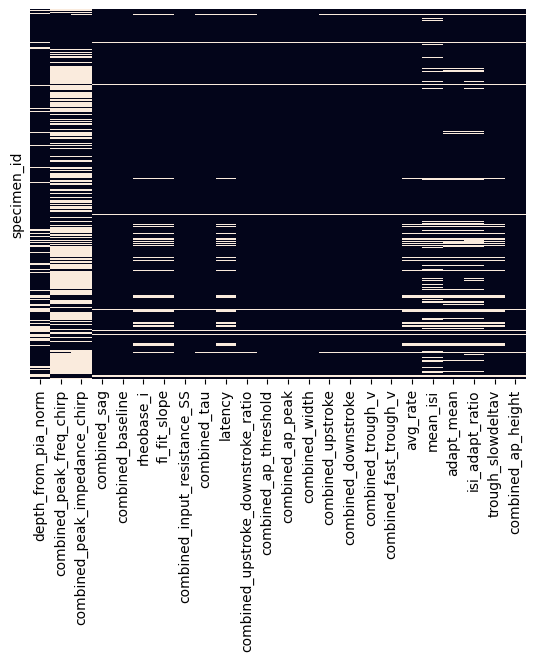

In [10]:
#before (plot missingness as boolean)
sns.heatmap(
    ephys[columns_to_impute].isna(),
    cbar=False,
    yticklabels=False
)

In [11]:
def impute_group(group):
    # Adjust n_neighbors if group is smaller than 100 cells
    n_neighbors = min(100, len(group))
    local_imputer = KNNImputer(n_neighbors=n_neighbors, weights="uniform")
    
    X = group[columns_to_impute]    
    imputed = local_imputer.fit_transform(X)

    return pd.DataFrame(imputed, index=group.index, columns=columns_to_impute)

# Apply groupwise imputation
ephys[columns_to_impute] = (ephys.groupby("subclass_label_Hierarchical", group_keys=False).apply(impute_group))

<Axes: ylabel='specimen_id'>

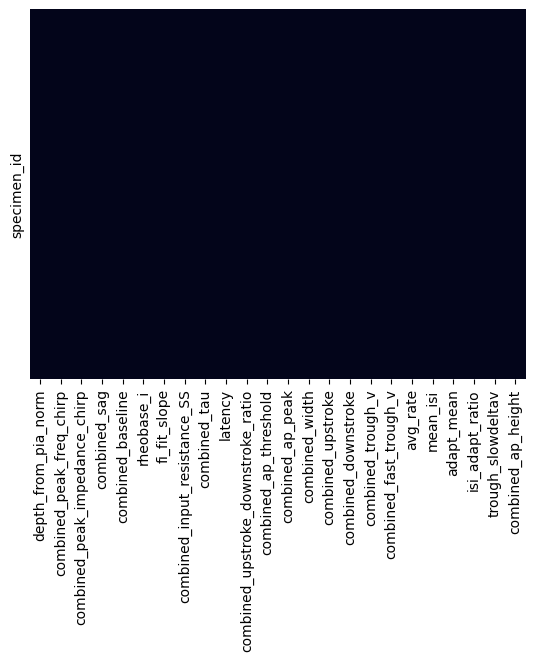

In [12]:
#after (plot missingness as boolean)
sns.heatmap(
    ephys[columns_to_impute].isna(),
    cbar=False,
    yticklabels=False
)

In [13]:
ephys.to_csv('/root/capsule/data/human/electrophysiology/features/20260722/ephys_features_imputed.csv')

FI data

In [14]:
old_fi_data = pd.read_csv('/root/capsule/data/human/electrophysiology/temp-20251008_data/20251008_ephys_fi_curve_data.csv')
new_fi_data = pd.read_csv('/root/capsule/data/human/electrophysiology/fi_features/20260722/features_exc_human_July2026_additional.csv')

old_fi_data = old_fi_data.rename(columns=lambda col: col.replace('nwg_', ''))
old_fi_data.drop(columns=['ephys', 'feature_count', 'specimen_name', 'subclass_label_Hierarchical'], inplace=True)

missing_cols_in_new_fi = [
 'avg_rate_10_long_square',
 'avg_rate_8_long_square',
 'stimulus_amplitude_10_long_square',
 'stimulus_amplitude_8_long_square']

new_fi_data[missing_cols_in_new_fi] = np.nan

new_fi_data = new_fi_data[old_fi_data.columns.tolist()]

fi_data = pd.concat([new_fi_data, old_fi_data], ignore_index=True)

In [15]:
old_fi_data.shape

(959, 23)

In [16]:
new_fi_data.shape

(14, 23)

In [17]:
fi_data = metadata[['cell_id', 'subclass_label_Hierarchical', 'Electrophysiology']].rename(
    columns={'cell_id': 'specimen_id'}).merge(fi_data, how='right', on='specimen_id')


fi_data = fi_data[fi_data['Electrophysiology'] == True]

fi_data

,specimen_id,subclass_label_Hierarchical,Electrophysiology,avg_rate_0_long_square,avg_rate_1_long_square,avg_rate_10_long_square,avg_rate_2_long_square,avg_rate_3_long_square,avg_rate_4_long_square,avg_rate_5_long_square,...,stimulus_amplitude_3_long_square,stimulus_amplitude_5_long_square,stimulus_amplitude_7_long_square,stimulus_amplitude_9_long_square,stimulus_amplitude_1_long_square,stimulus_amplitude_2_long_square,stimulus_amplitude_4_long_square,stimulus_amplitude_6_long_square,stimulus_amplitude_8_long_square,stimulus_amplitude_10_long_square
0,7.983386e+08,L2/3 IT,True,1.0,NaN,NaN,4.0,NaN,6.0,NaN,...,NaN,NaN,NaN,NaN,NaN,100.0,120.0,140.0,NaN,NaN
1,9.331946e+08,L6 CT,True,1.0,NaN,NaN,NaN,5.0,NaN,7.0,...,160.0,180.0,200.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.245582e+09,L5 IT,True,1.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.294106e+09,L5 ET,True,2.0,NaN,NaN,NaN,4.0,NaN,5.0,...,100.0,120.0,140.0,160.0,NaN,NaN,NaN,NaN,NaN,NaN
5,1.417481e+09,L2/3 IT,True,1.0,NaN,NaN,NaN,1.0,NaN,4.0,...,180.0,200.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
968,1.296492e+09,L6 CT,True,1.0,1.0,NaN,1.0,1.0,NaN,2.0,...,450.0,470.0,490.0,510.0,430.0,440.0,NaN,NaN,NaN,NaN
969,9.199898e+08,L2/3 IT,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
970,1.310108e+09,L6 CT,True,1.0,NaN,NaN,NaN,1.0,NaN,1.0,...,499.0,520.0,540.0,560.0,NaN,NaN,NaN,NaN,NaN,NaN
971,5.914557e+08,L4 IT,True,1.0,NaN,NaN,NaN,1.0,2.0,NaN,...,120.0,NaN,NaN,NaN,NaN,NaN,130.0,150.0,NaN,NaN


In [18]:
fi_data.to_csv('/root/capsule/data/human/electrophysiology/fi_features/20260722/ephys_fi_curve_data.csv')

Sparse PCA

In [19]:
old_spca = pd.read_csv('/root/capsule/data/human/electrophysiology/temp-20251008_data/sparse_pca_components_exc_human_May2025_flex.csv')
new_spca = pd.read_csv('/root/capsule/data/human/electrophysiology/sparce_pca/20260722/sparse_pca_components_exc_human_July2026_flex.csv')


In [20]:
old_spca.shape

(805, 48)

In [21]:
new_spca.shape

(816, 47)

In [22]:
old_spca.head(3)

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,37,38,39,40,41,42,43,44,45,46
0,1415831256,-1.320187,0.106383,-0.412445,-0.683360,1.342867,-0.158726,-0.650397,0.580827,0.879588,...,-0.188427,0.385906,-0.93579,0.098479,-0.054700,0.519373,-0.916815,-0.900241,-0.126121,-0.062038
1,1414830614,1.009837,1.667734,0.266233,-0.370542,-0.823339,0.567014,-1.291857,1.203542,-0.051408,...,1.358876,-0.395581,0.96576,-1.616826,-1.426429,-1.246547,0.812728,0.285468,0.553528,0.875356
2,1414810063,1.073532,-2.484278,1.399630,-3.096828,0.657820,-3.444365,1.317971,-1.246983,-2.162846,...,1.246954,-2.672848,1.57047,-2.009161,-2.013239,-1.823578,-0.434910,-0.327396,1.122330,-0.469724


In [23]:
new_spca.head(3)

,Unnamed: 0,0,1,2,3,4,5,6,7,8,...,36,37,38,39,40,41,42,43,44,45
0,1415831256,-1.329647,0.098497,-0.411435,-0.682072,1.344900,-0.178645,-0.639269,0.570844,0.878102,...,-0.189115,0.386762,-0.942226,0.109349,-0.042232,0.516692,-0.910209,-0.916639,-0.052413,-0.075733
1,1414830614,1.003653,1.657352,0.248965,-0.370042,-0.822600,0.525085,-1.246792,1.197478,-0.027342,...,1.360578,-0.393532,0.958604,-1.609498,-1.437216,-1.244540,0.828201,0.301159,0.505423,0.891075
2,1414810063,1.070269,-2.474873,1.407403,-3.083019,0.701924,-3.419754,1.398278,-1.260051,-2.144473,...,1.248354,-2.665176,1.563143,-2.022118,-2.005042,-1.823494,-0.413485,-0.246361,1.103773,-0.468661


In [24]:
set(old_spca.columns) - set(new_spca.columns)

{'46'}

In [25]:
new_spca.to_csv('/root/capsule/data/human/electrophysiology/sparce_pca/20260722/ephys_sparse_pca.csv')